# **Лабораторная работа 2. Односвязный список. Стек. Очередь. Амортизационный анализ. Динамический массив. Очередь на двух стеках. Куча.**

**Предварительная подготовка.**

**СКОПИРУЙТЕ ФАЙЛ**

ОБЯЗАТЕЛЬНО ЗДЕСЬ НАПИШИТЕ ФАМИЛИЮ.

Мамаев

Сдаете в LMS вы ipynb версию скачанную (не colab). При необходимости, вы можете сдать дополнительно файл (оформленный в любом читаемом виде).

Пожалуйста, не надо использовать ИИ для ответов на вопросы и написания кода. Отвечать на вопросы лучше прям здесь, под заданиями, где были написаны вопросы.

**Во всех задачах демонстрируйте вывод на каких-то тестовых данных.**

**Цель работы**

Реализовать базовые линейные структуры данных (односвязный список, стек, очередь, динамический массив, очередь на двух стеках) и двоичную кучу, экспериментально подтвердить их асимптотику и на практике попробовать применить амортизационный анализ.

**Баллы**

| Задание | Тема | Баллы |
|---|---|---|
| 1 | Односвязный список | 2 |
| 2 | Стек и очередь | 2 |
| 3 | Динамический массив и амортизационный анализ | 2 |
| 4 | Очередь на двух стеках | 2 |
| 5 | Двоичная куча | 2 |

# 0. Как измерять амортизированную стоимость операций

В прошлой лабораторной мы измеряли время работы **одного вызова** алгоритма. Со структурами данных все чуть иначе: отдельная операция может быть то дешёвой, то очень дорогой. Поэтому нас будут интересовать три величины:

1. **Фактическая стоимость $c_i$** каждой отдельной операции.
2. **Суммарная стоимость** $\sum_{j=1}^{i} c_j$ первых $i$ операций.
3. **Средняя (амортизированная) стоимость** $\frac{1}{i}\sum_{j=1}^{i} c_j$.

Как и раньше, время — величина довольно шумная и измерить замером времени будет проблемно, поэтому основным инструментом будет **подсчёт элементарных операций**.

Разберём всё на примере из лекции — **двоичного счётчика**. Операция `increment` прибавляет единицу; её стоимость — число изменённых битов.

In [1]:
import random
import sys
import time
import tracemalloc

import matplotlib.pyplot as plt
import numpy as np


def increment(bits):
    """bits[0] — младший бит. Возвращает число изменённых битов (стоимость операции)."""
    cost = 0
    i = 0
    while i < len(bits) and bits[i] == 1:
        bits[i] = 0
        cost += 1
        i += 1
    if i < len(bits):
        bits[i] = 1
        cost += 1
    return cost

Выполним $n$ операций и запишем стоимость каждой из них, а также накопленную сумму.

In [2]:
n = 1024
bits = [0] * 16

costs = []  # фактическая стоимость каждой операции
cumulative = []  # суммарная стоимость первых i операций
total = 0
for i in range(n):
    c = increment(bits)
    costs.append(c)
    total += c
    cumulative.append(total)

ops = np.arange(1, n + 1)
print("Максимальная стоимость одной операции:", max(costs))
print("Суммарная стоимость:", total, " граница 2n =", 2 * n)

Максимальная стоимость одной операции: 11
Суммарная стоимость: 2047  граница 2n = 2048


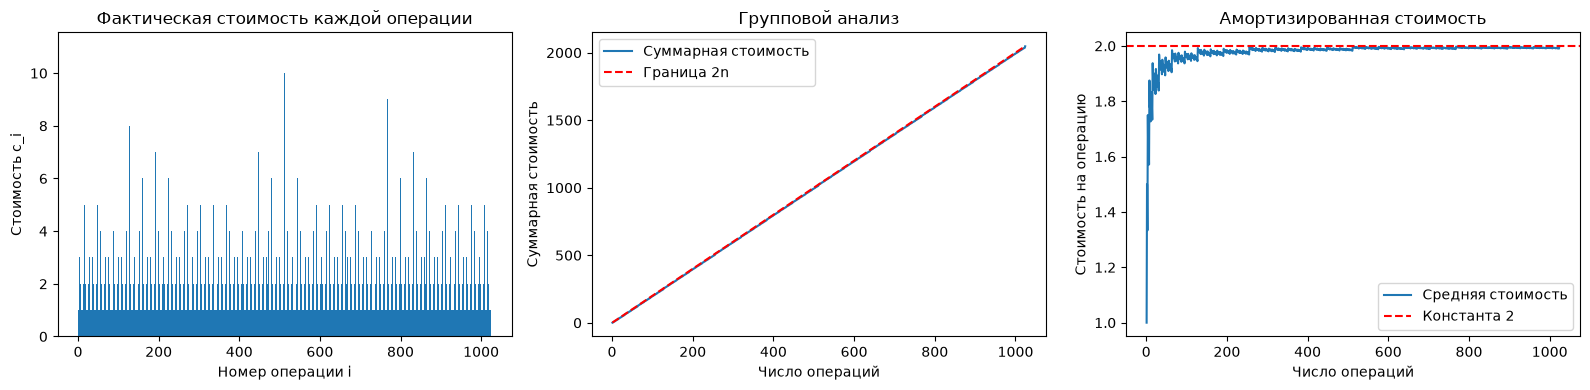

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(ops, costs, width=1.0)
axes[0].set_xlabel("Номер операции i")
axes[0].set_ylabel("Стоимость c_i")
axes[0].set_title("Фактическая стоимость каждой операции")

axes[1].plot(ops, cumulative, label="Суммарная стоимость")
axes[1].plot(ops, 2 * ops, "r--", label="Граница 2n")
axes[1].set_xlabel("Число операций")
axes[1].set_ylabel("Суммарная стоимость")
axes[1].set_title("Групповой анализ")
axes[1].legend()

axes[2].plot(ops, np.array(cumulative) / ops, label="Средняя стоимость")
axes[2].axhline(2, color="r", linestyle="--", label="Константа 2")
axes[2].set_xlabel("Число операций")
axes[2].set_ylabel("Стоимость на операцию")
axes[2].set_title("Амортизированная стоимость")
axes[2].legend()

plt.tight_layout()
plt.show()

Отдельные операции стоят до $\log_2 n + 1$, но суммарная стоимость лежит под прямой $2n$, а средняя стремится к константе $2$. Именно это и означает «амортизированное $O(1)$».

### Проверка через метод потенциалов

Можно проверить и метод потенциалов: при $\Phi$ = число единиц в счётчике амортизированная стоимость $\hat{c}_i = c_i + \Phi_i - \Phi_{i-1}$ должна быть не больше $2$ **для каждой** операции.

In [4]:
bits = [0] * 16
phi_prev = 0
amortized = []
for i in range(n):
    c = increment(bits)
    phi = sum(bits)
    amortized.append(c + phi - phi_prev)
    phi_prev = phi

print("max амортизированной стоимости:", max(amortized))
assert max(amortized) <= 2

max амортизированной стоимости: 2


## Как измерять время отдельной операции

Время одной быстрой операции — сотни наносекунд, и шум сравним с самим измерением. Поэтому:
* время **одной операции** измеряем через `perf_counter_ns()` и смотрим на форму графика (выбросы — ожидаемы);
* время **серии из N операций** измеряем целиком и повторяем замер несколько раз, отбрасывая минимум и максимум.

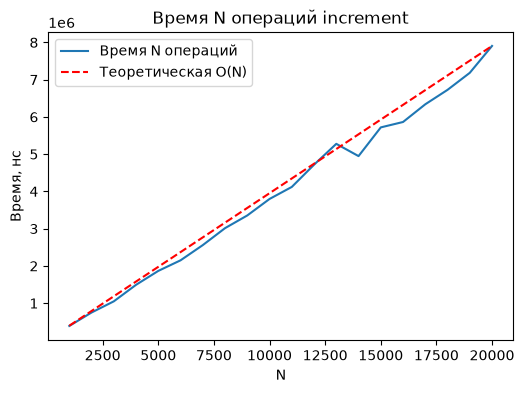

In [5]:
def measure_series(func, N, repeats=7):
    """Среднее время (в нс) выполнения func(N), без минимального и максимального замеров."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter_ns()
        func(N)
        end = time.perf_counter_ns()
        times.append(end - start)
    times.sort()
    times = times[1:-1]
    return sum(times) / len(times)


# пример: N инкрементов двоичного счётчика
def run_counter(N):
    bits = [0] * 32
    for _ in range(N):
        increment(bits)


N_GRID = list(range(1000, 20001, 1000))
counter_times = [measure_series(run_counter, N) for N in N_GRID]

plt.figure(figsize=(6, 4))
plt.plot(N_GRID, counter_times, label="Время N операций")
scale = counter_times[-1] / N_GRID[-1]
plt.plot(N_GRID, [scale * N for N in N_GRID], "r--", label="Теоретическая O(N)")
plt.xlabel("N")
plt.ylabel("Время, нс")
plt.title("Время N операций increment")
plt.legend()
plt.show()

## Как измерять память

Для оценки памяти будем использовать модуль `tracemalloc`: он показывает, сколько байт было выделено во время работы кода. `sys.getsizeof(obj)` возвращает размер **только самого объекта**, без объектов, на которые он ссылается.

In [6]:
def measure_memory(builder, N):
    """Пиковый объём памяти (в байтах), выделенной при вызове builder(N)."""
    tracemalloc.start()
    obj = builder(N)  # объект должен «жить», пока мы измеряем
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak


print("list из 10000 чисел:", measure_memory(lambda N: list(range(N)), 10_000), "байт")
print("getsizeof того же списка:", sys.getsizeof(list(range(10_000))), "байт")

list из 10000 чисел: 389175 байт
getsizeof того же списка: 80056 байт


# Задание 1 (2 балла). Односвязный список

**Односвязный список** — последовательность узлов, каждый из которых хранит значение и ссылку на следующий узел. Список хранит ссылку на первый узел `head` и (опционально) на последний `tail`.

```
head                               tail
 ↓                                  ↓
[1 | •]──→[2 | •]──→[3 | •]──→[4 | None]
```

В отличие от массива, элементы лежат в памяти не подряд, поэтому доступ по индексу — $O(n)$, зато вставка/удаление в начале — $O(1)$.

### Предварительная подготовка

1. Реализовать класс `Node` и класс `SinglyLinkedList` **с указателем на хвост** со следующим интерфейсом:

| Метод | Что делает |
|---|---|
| `push_front(x)` | добавить в начало |
| `push_back(x)` | добавить в конец |
| `pop_front()` | удалить и вернуть первый элемент (`IndexError`, если пуст) |
| `pop_back()` | удалить и вернуть последний элемент (`IndexError`, если пуст) |
| `get(i)` | значение по индексу (`IndexError`, если индекс вне диапазона) |
| `find(x)` | `True`, если значение есть в списке |
| `remove(x)` | удалить первое вхождение `x`, вернуть `True`/`False` |
| `reverse()` | развернуть список **на месте**, без создания новых узлов |
| `__len__`, `__iter__`, `__str__` | длина за $O(1)$, обход, строка вида `1 -> 2 -> 3` |

2. Реализовать класс `SinglyLinkedListNoTail` — тот же список, но **без** указателя `tail` (достаточно методов `push_front`, `push_back`, `pop_front`, `__len__`, `__iter__`).
3. Для подсчёта операций добавьте в оба класса счётчик `self.ops`: увеличивайте его на 1 при каждом переходе по ссылке `node = node.next` и при каждом создании узла.
4. Для каждого метода указать асимптотику и **обосновать** её. Объяснить, почему `pop_back` работает за $O(n)$ даже при наличии `tail`.

In [ ]:
class Node: ...


class SinglyLinkedList:
    def push_front(self, x: Node): ...
    def push_back(self): ...
    def pop_front(self): ...
    def get(self): ...
    def find(self): ...
    def remove(self): ...
    def reverse(self): ...
    def __len__(self): ...
    def __iter__(self): ...
    def __str__(self):
        return ""

Запустите проверку. Все `assert` должны пройти.

In [7]:
ll = SinglyLinkedList()
assert len(ll) == 0 and str(ll) == ""
for x in [2, 3, 4]:
    ll.push_back(x)
ll.push_front(1)
assert str(ll) == "1 -> 2 -> 3 -> 4" and len(ll) == 4
assert list(ll) == [1, 2, 3, 4]
assert ll.get(0) == 1 and ll.get(3) == 4
assert ll.find(3) and not ll.find(10)
assert ll.remove(3) and not ll.remove(10)
assert list(ll) == [1, 2, 4]
ll.reverse()
assert list(ll) == [4, 2, 1]
ll.push_back(7)  # tail должен быть корректным после reverse
assert list(ll) == [4, 2, 1, 7]
assert ll.pop_back() == 7 and ll.pop_front() == 4
assert list(ll) == [2, 1] and len(ll) == 2
ll.pop_back()
ll.pop_back()
assert len(ll) == 0 and list(ll) == []
ll.push_back(5)  # после опустошения head и tail должны обнулиться
assert list(ll) == [5]
for method in (ll.pop_front, ll.pop_back):
    ll2 = SinglyLinkedList()
    try:
        getattr(ll2, method.__name__)()
        assert False, "ожидалось IndexError"
    except IndexError:
        pass

nt = SinglyLinkedListNoTail()
for x in range(5):
    nt.push_back(x)
assert list(nt) == [0, 1, 2, 3, 4] and nt.pop_front() == 0 and len(nt) == 4
print("Все проверки пройдены!")

NameError: name 'SinglyLinkedList' is not defined

### Провести эксперименты

5. Взять размеры от 500 до 5000 с шагом 500.
6. Для каждого размера N построить структуру из N элементов следующими способами:
  * `SinglyLinkedList.push_front` (N раз);
  * `SinglyLinkedList.push_back` (N раз);
  * `SinglyLinkedListNoTail.push_back` (N раз);
  * `list.append` (N раз);
  * `list.insert(0, x)` (N раз).
7. Для каждого способа и каждого N:
  * подсчитать среднее время выполнения (не менее 10 повторных замеров);
  * подсчитать количество операций (для ваших классов — счётчик `ops`).
8. Сравнить доступ к элементу в середине: `SinglyLinkedList.get(N // 2)` и `list[N // 2]` (время).
9. С помощью `tracemalloc` измерить память, занимаемую `SinglyLinkedList` и `list` из N целых чисел.

### Построить графики

10. На одном графике — время построения структуры всеми пятью способами. Теоретические кривые $O(N)$ и $O(N^2)$ — пунктиром.
11. На одном графике — количество операций для `push_front`, `push_back` с хвостом и без хвоста.
12. На одном графике — время доступа к середине для списка и `list`.
13. На одном графике — память связного списка и `list`. Подпишите, во сколько раз отличаются значения при N = 5000.

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. Почему `push_back` без `tail` дал квадратичное суммарное время? Сколько операций он выполнил при N = 5000 и как это согласуется с формулой $\frac{N(N-1)}{2}$?
3. И `list.insert(0, x)`, и `SinglyLinkedListNoTail.push_back` квадратичны. Какой из них быстрее на практике и почему?
4. Во сколько раз связный список занимает больше памяти, чем `list`? Из чего складывается память одного узла?
5. В каких задачах связный список действительно выгоднее динамического массива?

# Задание 2 (2 балла). Стек и очередь

**Стек** — структура LIFO (последним пришёл — первым ушёл): `push`, `pop`, `peek`.

**Очередь** — структура FIFO (первым пришёл — первым ушёл): `enqueue`, `dequeue`, `peek`.

Обе структуры можно реализовать как на массиве, так и на связном списке. Важно выбрать, с какого конца добавлять и удалять, чтобы все операции работали за $O(1)$.

### Предварительная подготовка

1. Реализовать четыре класса с единым интерфейсом. Методы `pop`/`dequeue`/`peek` на пустой структуре должны бросать `IndexError`.

| Класс | Основа | Методы |
|---|---|---|
| `ArrayStack` | `list` | `push`, `pop`, `peek`, `is_empty`, `__len__` |
| `LinkedStack` | собственные узлы `Node` | `push`, `pop`, `peek`, `is_empty`, `__len__` |
| `LinkedQueue` | собственные узлы, `head` + `tail` | `enqueue`, `dequeue`, `peek`, `is_empty`, `__len__` |
| `NaiveListQueue` | `list`, удаление через `pop(0)` | `enqueue`, `dequeue`, `peek`, `is_empty`, `__len__` |

2. Используя **ваш** `LinkedStack`, реализовать:
   * `is_valid_brackets(s)` — проверку правильности скобочной последовательности из `()[]{}`;
   * `eval_rpn(tokens)` — вычисление выражения в обратной польской записи (операции `+ - * /`, деление — с отбрасыванием дробной части к нулю).
3. Для каждой операции каждого класса указать асимптотику и обосновать её. Объяснить, почему в `LinkedQueue` добавлять нужно в хвост, а удалять из головы, а не наоборот.

In [ ]:
for S in (ArrayStack, LinkedStack):
    s = S()
    assert s.is_empty() and len(s) == 0
    for x in [1, 2, 3]:
        s.push(x)
    assert s.peek() == 3 and len(s) == 3
    assert [s.pop(), s.pop(), s.pop()] == [3, 2, 1]
    try:
        s.pop()
        assert False
    except IndexError:
        pass

for Q in (LinkedQueue, NaiveListQueue):
    q = Q()
    assert q.is_empty()
    for x in [1, 2, 3]:
        q.enqueue(x)
    assert q.peek() == 1 and len(q) == 3
    assert q.dequeue() == 1
    q.enqueue(4)
    assert [q.dequeue(), q.dequeue(), q.dequeue()] == [2, 3, 4]
    assert q.is_empty()
    q.enqueue(5)  # проверка после опустошения
    assert q.dequeue() == 5
    try:
        q.dequeue()
        assert False
    except IndexError:
        pass

assert (
    is_valid_brackets("()[]{}")
    and is_valid_brackets("{[()()]}")
    and is_valid_brackets("")
)
assert (
    not is_valid_brackets("(]")
    and not is_valid_brackets("([)]")
    and not is_valid_brackets("((")
)
assert not is_valid_brackets(")")
assert eval_rpn(["2", "1", "+", "3", "*"]) == 9
assert eval_rpn(["4", "13", "5", "/", "+"]) == 6
assert (
    eval_rpn(["10", "6", "9", "3", "+", "-11", "*", "/", "*", "17", "+", "5", "+"])
    == 22
)
print("Все проверки пройдены!")

### Провести эксперименты

4. Взять N от 5000 до 50000 с шагом 5000.
5. Для стеков (`ArrayStack`, `LinkedStack`) измерить среднее время серии «N раз `push`, затем N раз `pop`».
6. Для очередей (`LinkedQueue`, `NaiveListQueue`, `collections.deque`, `queue.Queue`) измерить среднее время серии «N раз добавить, затем N раз извлечь».
7. Сгенерировать правильные скобочные последовательности длины от 10 000 до 100 000 и измерить время `is_valid_brackets`.

### Построить графики

8. На одном графике — время для двух стеков. Теоретическая кривая $O(N)$ — пунктиром.
9. На одном графике — время для четырёх очередей. Теоретические кривые $O(N)$ и $O(N^2)$ — пунктиром.
10. Время `is_valid_brackets` от длины строки с теоретической кривой.

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. Какой стек быстрее — на `list` или на узлах? Почему, если оба работают за $O(1)$?
3. Почему `NaiveListQueue` квадратичен, хотя при небольших N может работать быстро?
4. Почему `queue.Queue` заметно медленнее `deque`? Когда его всё-таки стоит использовать?
5. Какую из реализованных очередей вы бы выбрали для реальной программы и почему?

# Задание 3 (3 балла). Динамический массив и амортизационный анализ

**Динамический массив** хранит блок памяти ёмкостью `capacity`, в котором заняты первые `size` ячеек. Когда места нет, выделяется новый блок большего размера и все элементы копируются.

* При **умножении** ёмкости на $\alpha > 1$ добавление в конец работает за амортизированное $O(1)$ (суммарно копирований $O\!\left(\frac{n}{\alpha - 1}\right)$).
* При **увеличении на константу** $c$ — за амортизированное $O(n)$ (суммарно $\approx \frac{n^2}{2c}$ копирований).
* Для удвоения работает потенциал $\Phi = 2\cdot\text{size} - \text{capacity}$, и $\hat{c}_i = c_i + \Delta\Phi \le 3$.
* Уменьшать ёмкость вдвое нужно, когда массив заполнен на $\frac14$, а не на $\frac12$, иначе возникает «пробуксовка».

### Предварительная подготовка

1. Реализовать класс `DynamicArray(growth=2.0, additive=None, shrink="quarter", initial_capacity=1)`:
   * если `additive` задан, новая ёмкость = `capacity + additive`, иначе `max(capacity + 1, int(capacity * growth))`;
   * `shrink` принимает значения `"quarter"` (сжимать вдвое при `size <= capacity // 4`), `"half"` (сжимать вдвое при `size <= capacity // 2`) или `None` (не сжимать); ёмкость не опускается ниже `initial_capacity`;
   * хранилище — **только** список фиксированной длины `[None] * capacity`; методы `append`/`insert`/`pop` встроенного списка для хранилища использовать **нельзя**;
   * методы: `append(x)`, `pop()`, `__getitem__`, `__setitem__`, `__len__`, свойство `capacity`;
   * счётчики: `self.writes` (запись нового элемента), `self.copies` (копирование при изменении ёмкости), `self.last_cost` — стоимость последней операции (`1` + число копирований для `append`; `1` + число копирований для `pop`).
2. Доказать **тремя методами** (групповой, бухгалтерский, потенциалов), что амортизированная стоимость `append` при удвоении — $O(1)$.
3. Доказать, что при `additive = c` суммарная стоимость $n$ операций — $\Theta(n^2)$.
4. Привести последовательность операций, на которой правило `"half"` даёт $\Theta(n)$ на каждую операцию.

In [ ]:
a = DynamicArray()
for i in range(10):
    a.append(i)
assert len(a) == 10 and [a[i] for i in range(10)] == list(range(10))
assert a.capacity == 16
assert a.copies == 1 + 2 + 4 + 8 and a.writes == 10
a[3] = 100
assert a[3] == 100
try:
    a[10]
    assert False
except IndexError:
    pass

a.append(10)
assert a.last_cost == 1
b = DynamicArray()
for i in range(8):
    b.append(i)
b.append(8)
assert b.last_cost == 1 + 8  # 8 копирований + запись

c = DynamicArray(additive=10, initial_capacity=10)
for i in range(35):
    c.append(i)
assert c.capacity == 40 and c.copies == 10 + 20 + 30

d = DynamicArray(shrink="quarter")
for i in range(16):
    d.append(i)
assert d.capacity == 16
for _ in range(12):
    d.pop()
assert len(d) == 4 and d.capacity == 8 and [d[i] for i in range(4)] == [0, 1, 2, 3]

e = DynamicArray(shrink=None)
for i in range(16):
    e.append(i)
for _ in range(16):
    e.pop()
assert e.capacity == 16 and len(e) == 0
try:
    e.pop()
    assert False
except IndexError:
    pass
print("Все проверки пройдены!")

### Провести эксперименты

**Эксперимент 3.1. Стоимость отдельных операций.**

5. Выполнить $n = 2000$ операций `append` для `DynamicArray()` и записать `last_cost` каждой операции, суммарную стоимость и среднюю стоимость.
6. Для каждой операции вычислить потенциал $\Phi = 2\cdot\text{size} - \text{capacity}$ и амортизированную стоимость $\hat{c}_i = c_i + \Phi_i - \Phi_{i-1}$. Проверить через `assert`, что $\hat{c}_i \le 3$ (первую операцию можно пропустить).

**Эксперимент 3.2. Коэффициент роста.**

7. Для N от 1000 до 50000 с шагом 1000 и стратегий `growth` ∈ {1.25, 1.5, 2, 3}, `additive` ∈ {10, 100} подсчитать:
   * суммарное число копирований `copies`;
   * долю неиспользуемой памяти $\frac{\text{capacity} - \text{size}}{\text{capacity}}$ после N добавлений;
   * среднее время N добавлений (не менее 5 повторных замеров).

**Эксперимент 3.3. Пробуксовка.**

8. Для правил `"half"` и `"quarter"`: заполнить массив до размера $2^k$ ($k$ от 8 до 14), затем выполнить 1000 пар операций «`append`, `pop`». Подсчитать суммарное число копирований за эти 2000 операций.

**Эксперимент 3.4. Встроенный `list`.**

9. Добавлять в пустой `list` элементы по одному (до 10 000) и с помощью `sys.getsizeof` зафиксировать моменты, когда меняется размер выделенной памяти. Оценить коэффициент роста CPython.
10. Измерить `perf_counter_ns()` время **каждой** из 100 000 операций `list.append` и найти номера операций с аномально большим временем.

### Построить графики

11. Эксперимент 3.1: три графика (как в разделе 0) — стоимость каждой операции, суммарная стоимость с границей $3n$, средняя стоимость с константой $3$. Отдельно — график $\hat{c}_i$.
12. Эксперимент 3.2: на одном графике — суммарное число копирований для всех стратегий; теоретические кривые $\frac{n}{\alpha-1}$ и $\frac{n^2}{2c}$ пунктиром. Лучше использовать логарифмическую шкалу по оси Y.
13. Эксперимент 3.2: на одном графике — доля неиспользуемой памяти для всех мультипликативных стратегий.
14. Эксперимент 3.3: число копирований для двух правил сжатия в зависимости от $2^k$.
15. Эксперимент 3.4: размер `list` в байтах от длины (ступенчатый график) и время каждого `append` (точечный график).

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. Чем отличается амортизированная оценка от оценки среднего случая из прошлой лабораторной?
3. Какой коэффициент роста вы бы выбрали и почему? Опишите компромисс между временем и памятью.
4. Какой коэффициент роста у `list` в вашей версии Python? Совпадают ли «скачки» времени `append` с моментами перевыделения памяти? Почему совпадение неидеальное?
5. Объясните пробуксовку на результатах эксперимента 3.3.
6. Почему динамический массив с амортизированным $O(1)$ может не подойти для системы реального времени (например, управления двигателем)?

# Задание 4 (3 балла). Очередь на двух стеках

Очередь реализуется на двух стеках `in_stack` и `out_stack`:
* `enqueue(x)` — `push` в `in_stack`;
* `dequeue()` — если `out_stack` пуст, **все** элементы перекладываются из `in_stack` в `out_stack`; затем `pop` из `out_stack`.

Каждый элемент перекладывается не более одного раза, поэтому амортизированная стоимость всех операций — $O(1)$. Потенциал: $\Phi = 2\cdot|\text{in\_stack}|$.

Если хранить в стеках пары (значение, минимум ниже), то получится **очередь с минимумом**, с помощью которой задача о минимуме в скользящем окне решается за $O(n)$.

### Предварительная подготовка

1. Реализовать класс `TwoStackQueue` на двух стеках (можно использовать `ArrayStack` из задания 2 или `list` с операциями только на конце). Методы: `enqueue`, `dequeue`, `peek`, `is_empty`, `__len__`. Счётчики: `self.stack_ops` — общее число операций `push`/`pop` над внутренними стеками, `self.last_cost` — число таких операций в последнем вызове.
2. Реализовать классы `MinStack` (`push`, `pop`, `get_min`, `__len__`) и `MinQueue` (`enqueue`, `dequeue`, `get_min`, `__len__`), где все операции работают за амортизированное $O(1)$.
3. Реализовать `sliding_window_min(arr, k)` с помощью `MinQueue` и наивную версию `sliding_window_min_naive(arr, k)` за $O(nk)$.
4. Доказать **тремя методами**, что амортизированная стоимость операций `TwoStackQueue` — $O(1)$. Указать худший случай для одной операции.

In [ ]:
from collections import deque

q = TwoStackQueue()
for x in [1, 2, 3]:
    q.enqueue(x)
assert (
    q.dequeue() == 1 and q.last_cost == 3 + 3 + 1
)  # 3 pop + 3 push при перекладке + 1 pop
q.enqueue(4)
assert [q.dequeue(), q.dequeue()] == [2, 3] and q.last_cost == 1
assert q.peek() == 4 and len(q) == 1
assert q.dequeue() == 4 and q.is_empty()
try:
    q.dequeue()
    assert False
except IndexError:
    pass

# случайный тест против deque
random.seed(0)
q, ref = TwoStackQueue(), deque()
for _ in range(10000):
    if ref and random.random() < 0.45:
        assert q.dequeue() == ref.popleft()
    else:
        x = random.randint(-100, 100)
        q.enqueue(x)
        ref.append(x)
    assert len(q) == len(ref)

ms = MinStack()
for x in [5, 3, 7, 3, 1]:
    ms.push(x)
assert ms.get_min() == 1
ms.pop()
assert ms.get_min() == 3
ms.pop()
assert ms.get_min() == 3
ms.pop()
ms.pop()
assert ms.get_min() == 5

mq = MinQueue()
for x in [4, 2, 12, 3]:
    mq.enqueue(x)
assert mq.get_min() == 2
mq.dequeue()
assert mq.get_min() == 2
mq.dequeue()
assert mq.get_min() == 3

assert sliding_window_min([4, 2, 12, 3, 8, 1, 7], 3) == [2, 2, 3, 1, 1]
arr = [random.randint(0, 1000) for _ in range(500)]
for k in (1, 5, 50, 500):
    assert sliding_window_min(arr, k) == sliding_window_min_naive(arr, k)
print("Все проверки пройдены!")

### Провести эксперименты

**Эксперимент 4.1. Стоимость отдельных операций.** Для каждого из трёх сценариев записать `last_cost` каждой операции, суммарную и среднюю стоимость, а также $\hat{c}_i = c_i + \Delta\Phi$:
* сценарий A: 1000 `enqueue`, затем 1000 `dequeue`;
* сценарий B: 100 блоков «10 `enqueue`, 10 `dequeue`»;
* сценарий C: 2000 случайных операций (`enqueue` с вероятностью 0.6, иначе `dequeue`, если очередь не пуста).

**Эксперимент 4.2. Сравнение очередей.** Для N от 5000 до 50000 с шагом 5000 измерить среднее время серии «N `enqueue`, затем N `dequeue`» и серии «N раз: `enqueue`, `dequeue`» для `TwoStackQueue`, `LinkedQueue`, `NaiveListQueue` (из задания 2) и `deque`.

**Эксперимент 4.3. Когда амортизация ломается.** Создать `TwoStackQueue` из N элементов (только `enqueue`). Сохранить её копию (`copy.deepcopy`) и 100 раз выполнить `dequeue` **на свежей копии того же состояния**. Подсчитать суммарную стоимость этих 100 операций для N от 1000 до 10000 и сравнить с 100 последовательными `dequeue` на одной очереди.

**Эксперимент 4.4. Скользящее окно.** Для массива из 20 000 случайных чисел и $k$ ∈ {10, 50, 100, 500, 1000, 2000} измерить время `sliding_window_min` и `sliding_window_min_naive`.

### Построить графики

16. Эксперимент 4.1: для каждого сценария — стоимость каждой операции и суммарная стоимость с границей $4 \cdot (\text{число enqueue})$.
17. Эксперимент 4.2: на одном графике — время всех очередей (отдельно для двух серий). Теоретические кривые пунктиром.
18. Эксперимент 4.3: суммарная стоимость 100 `dequeue` в двух режимах в зависимости от N.
19. Эксперимент 4.4: время двух решений в зависимости от $k$.

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. В каком сценарии эксперимента 4.1 максимальная стоимость одной операции наибольшая? Почему при этом средняя стоимость во всех сценариях ограничена константой?
3. Почему `TwoStackQueue` медленнее `deque`, хотя асимптотика одинаковая?
4. Объясните результат эксперимента 4.3. Почему амортизированная оценка перестаёт работать, если «откатывать» состояние структуры?
5. Почему перекладывать элементы можно только при пустом `out_stack`? Что сломается, если перекладывать при каждом `dequeue`?
6. Начиная с какого $k$ решение через `MinQueue` выигрывает у наивного?

# Задание 5 (2 балла). Двоичная куча

**Двоичная куча (min-heap)** — почти полное двоичное дерево, хранящееся в массиве: у элемента с индексом $i$ дети имеют индексы $2i+1$ и $2i+2$, родитель — $\lfloor (i-1)/2 \rfloor$. Значение в каждом узле не больше значений в детях, поэтому минимум всегда в `heap[0]`.

* `push` — добавить в конец и **просеять вверх** (`sift_up`): $O(\log n)$.
* `pop` — переставить последний элемент в корень и **просеять вниз** (`sift_down`): $O(\log n)$.
* `heapify` — построить кучу из массива, вызывая `sift_down` от середины к началу: $O(n)$.

### Предварительная подготовка

1. Реализовать класс `MinHeap` с методами `push`, `pop`, `peek`, `__len__` и методом класса `MinHeap.heapify(arr)` (построение за $O(n)$). Добавить счётчик сравнений `self.comparisons`.
2. Реализовать `heap_sort(arr)` с помощью вашей кучи.
3. Реализовать `top_k(arr, k)` — $k$ наибольших элементов массива за $O(n \log k)$ с использованием кучи размера $k$.
4. Доказать, что `heapify` работает за $O(n)$, а построение через $n$ вызовов `push` — за $O(n \log n)$.

In [ ]:
h = MinHeap()
for x in [5, 3, 8, 1, 9, 2]:
    h.push(x)
assert h.peek() == 1 and len(h) == 6
assert [h.pop() for _ in range(6)] == [1, 2, 3, 5, 8, 9]
try:
    h.pop()
    assert False
except IndexError:
    pass

data = [random.randint(-1000, 1000) for _ in range(2000)]
h2 = MinHeap.heapify(data[:])
assert [h2.pop() for _ in range(len(data))] == sorted(data)
assert heap_sort(data[:]) == sorted(data)
assert sorted(top_k(data, 10)) == sorted(data)[-10:]
print("Все проверки пройдены!")

### Провести эксперименты

5. Для N от 10 000 до 200 000 с шагом 10 000 подсчитать число сравнений при построении кучи через `heapify` и через N вызовов `push` (на случайных данных и на данных, отсортированных по убыванию).
6. Сравнить время `heap_sort`, `heapq` (`heapify` + `heappop`) и `sorted`.
7. Сравнить время `top_k(arr, 10)` и `sorted(arr)[-10:]` для N от 100 000 до 1 000 000.

### Построить графики

8. На одном графике — число сравнений для двух способов построения (два типа данных). Теоретические кривые $O(n)$ и $O(n \log n)$ — пунктиром.
9. На одном графике — время трёх сортировок.
10. На одном графике — время двух способов поиска top-k.

**Требования к графикам:**

Сделайте
* Подписи осей
* Заголовок
* Легенду с пояснением всех линий
* Теоретические кривые — пунктирной линией

### Анализ результатов + ответы на вопросы

1. Сравните теоретическую асимптотику с экспериментальными данными. Совпадает ли форма кривых?
2. Почему `heapify` работает за $O(n)$, хотя вызывает `sift_down` $\frac{n}{2}$ раз, а каждый `sift_down` может стоить $O(\log n)$?
3. На каких данных построение через `push` достигает худшего случая?
4. Почему `heapq` намного быстрее вашей реализации?
5. Для каких задач куча подходит лучше, чем отсортированный массив?

## Выводы

Сделайте общие выводы и заполните таблицу! В каждой ячейке укажите асимптотику в худшем случае / амортизированную и подтвердилась ли она экспериментально.

| Структура \ Операция | Добавление | Удаление | Доступ по индексу / к вершине | Поиск | Память |
|---|---|---|---|---|---|
| **`SinglyLinkedList`** | | | | | |
| **`ArrayStack`** | | | | | |
| **`LinkedStack`** | | | | | |
| **`LinkedQueue`** | | | | | |
| **`NaiveListQueue`** | | | | | |
| **`DynamicArray` (×2)** | | | | | |
| **`DynamicArray` (+c)** | | | | | |
| **`TwoStackQueue`** | | | | | |
| **`MinHeap`** | | | | | |

**Контрольные вопросы**

1. Что такое амортизированная стоимость операции? Чем она отличается от стоимости в худшем и среднем случаях?
2. Сформулируйте групповой метод, метод бухгалтерского учёта и метод потенциалов. Какие условия должна удовлетворять функция потенциала?
3. Почему ёмкость динамического массива нужно умножать, а не увеличивать на константу?
4. Почему сжимать массив нужно при заполнении на четверть, а не наполовину?
5. Почему в очереди на двух стеках каждый элемент перекладывается не более одного раза?
6. Как реализовать стек и очередь так, чтобы все операции работали за $O(1)$ в худшем случае?
7. Чем связный список хуже динамического массива на современных процессорах?